# Unemployment Analysis with Python

**Internship:** Oasis Infobyte  
**Domain:** Data Science  
**Task:** Task 2 – Unemployment Analysis with Python  
**Author:** Noor Afshan

## 1. Introduction

Unemployment is an important economic indicator that reflects the availability of jobs in a country. This project focuses on analysing unemployment trends in India using Python.

The analysis explores changes in unemployment rates across different Indian states, compares rural and urban areas, and examines unemployment trends before and during the COVID-19 period covered by the dataset.

## 2. Objectives

- Analyse unemployment trends over time.
- Compare unemployment rates across different states.
- Identify the top 10 regions with the highest average unemployment rates.
- Study the relationship between unemployment, employment and labour participation.
- Compare rural and urban unemployment rates.
- Examine unemployment before and during the COVID-19 period.

## 3. Dataset

**Dataset:** Unemployment in India

**Source:** [Kaggle – Unemployment in India](https://www.kaggle.com/datasets/gokulrajkmv/unemployment-in-india)

The dataset contains unemployment-related information from May 2019 to June 2020 across 28 Indian regions.

## 4. Tools and Libraries

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn

## 5. Project Workflow

1. Importing libraries
2. Loading the dataset
3. Data cleaning and preprocessing
4. Exploratory Data Analysis (EDA)
5. Data visualization
6. Regional and rural-urban comparisons
7. COVID-19 period comparison
8. Key observations and conclusion

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [22]:
df = pd.read_csv("Unemployment in India.csv")

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [23]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (768, 7)

Column Names:
Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: 

In [24]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Check completely empty rows
print("Completely empty rows:", df.isnull().all(axis=1).sum())

# Remove completely empty rows
df = df.dropna(how="all")

# Check missing values again
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nUpdated Dataset Shape:", df.shape)

Completely empty rows: 28

Missing values after cleaning:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

Updated Dataset Shape: (740, 7)


In [25]:
# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

# Check data types
print(df.dtypes)

# Display first 5 rows
df.head()

Region                                             object
Date                                       datetime64[ns]
Frequency                                          object
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                               object
dtype: object


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [26]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [27]:
# Statistical summary of numerical columns
df.describe()

,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378496,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


In [28]:
print("Total Regions:", df["Region"].nunique())

print("\nRegions:")
print(sorted(df["Region"].unique()))

print("\nArea Categories:")
print(df["Area"].value_counts())

print("\nFrequency Categories:")
print(df["Frequency"].value_counts())

Total Regions: 28

Regions:
['Andhra Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

Area Categories:
Area
Urban    381
Rural    359
Name: count, dtype: int64

Frequency Categories:
Frequency
Monthly     381
 Monthly    359
Name: count, dtype: int64


In [29]:
# Remove extra spaces from text values
df["Region"] = df["Region"].str.strip()
df["Frequency"] = df["Frequency"].str.strip()
df["Area"] = df["Area"].str.strip()

# Check categories again
print("Frequency Categories:")
print(df["Frequency"].value_counts())

print("\nArea Categories:")
print(df["Area"].value_counts())

print("\nDataset Shape:", df.shape)

Frequency Categories:
Frequency
Monthly    740
Name: count, dtype: int64

Area Categories:
Area
Urban    381
Rural    359
Name: count, dtype: int64

Dataset Shape: (740, 7)


In [30]:
print("Starting Date:", df["Date"].min())
print("Ending Date:", df["Date"].max())

print("\nMonthly Records:")
print(df["Date"].dt.to_period("M").value_counts().sort_index())

Starting Date: 2019-05-31 00:00:00
Ending Date: 2020-06-30 00:00:00

Monthly Records:
Date
2019-05    54
2019-06    54
2019-07    54
2019-08    53
2019-09    52
2019-10    55
2019-11    55
2019-12    53
2020-01    53
2020-02    53
2020-03    52
2020-04    51
2020-05    51
2020-06    50
Freq: M, Name: count, dtype: int64


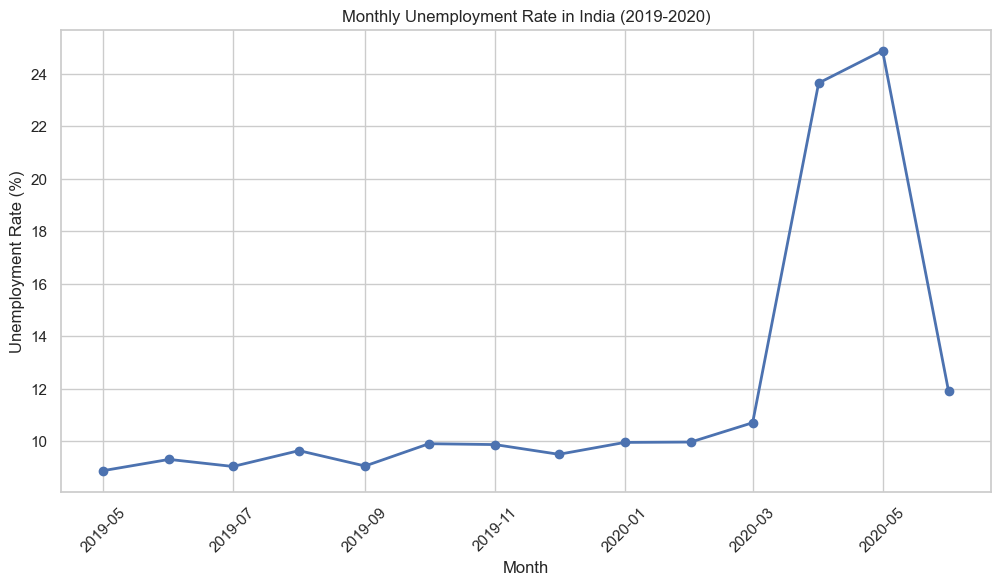

In [31]:
# Calculate monthly average unemployment rate
monthly_unemployment = df.groupby(
    df["Date"].dt.to_period("M")
)["Estimated Unemployment Rate (%)"].mean()

# Convert period index into datetime
monthly_unemployment.index = monthly_unemployment.index.to_timestamp()

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Unemployment Rate in India (2019-2020)")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.grid(True)

plt.savefig(
    "images/01_monthly_unemployment_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

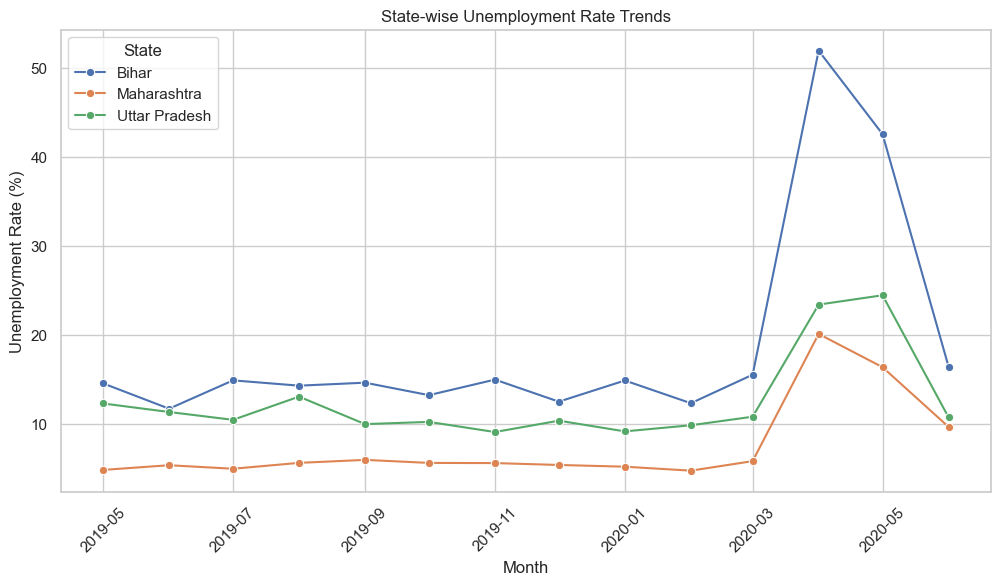

In [32]:
# Select three states
selected_states = ["Uttar Pradesh", "Bihar", "Maharashtra"]

state_data = df[df["Region"].isin(selected_states)].copy()

# Calculate monthly average unemployment rate for each state
state_monthly = state_data.groupby(
    [state_data["Date"].dt.to_period("M"), "Region"]
)["Estimated Unemployment Rate (%)"].mean().reset_index()

state_monthly["Date"] = state_monthly["Date"].dt.to_timestamp()

# Create line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=state_monthly,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    marker="o"
)

plt.title("State-wise Unemployment Rate Trends")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="State")
plt.grid(True)

plt.savefig(
    "images/02_statewise_unemployment_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

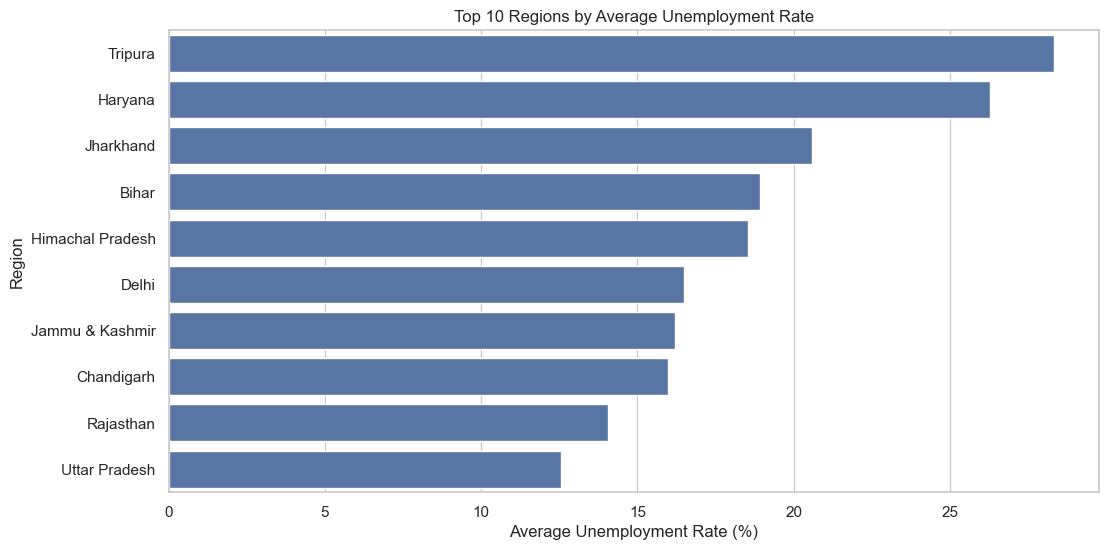

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64


In [33]:
# Calculate average unemployment rate by region
top_10_states = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_states.values,
    y=top_10_states.index
)

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.savefig(
    "images/03_top_10_unemployment_regions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display values
print(top_10_states)

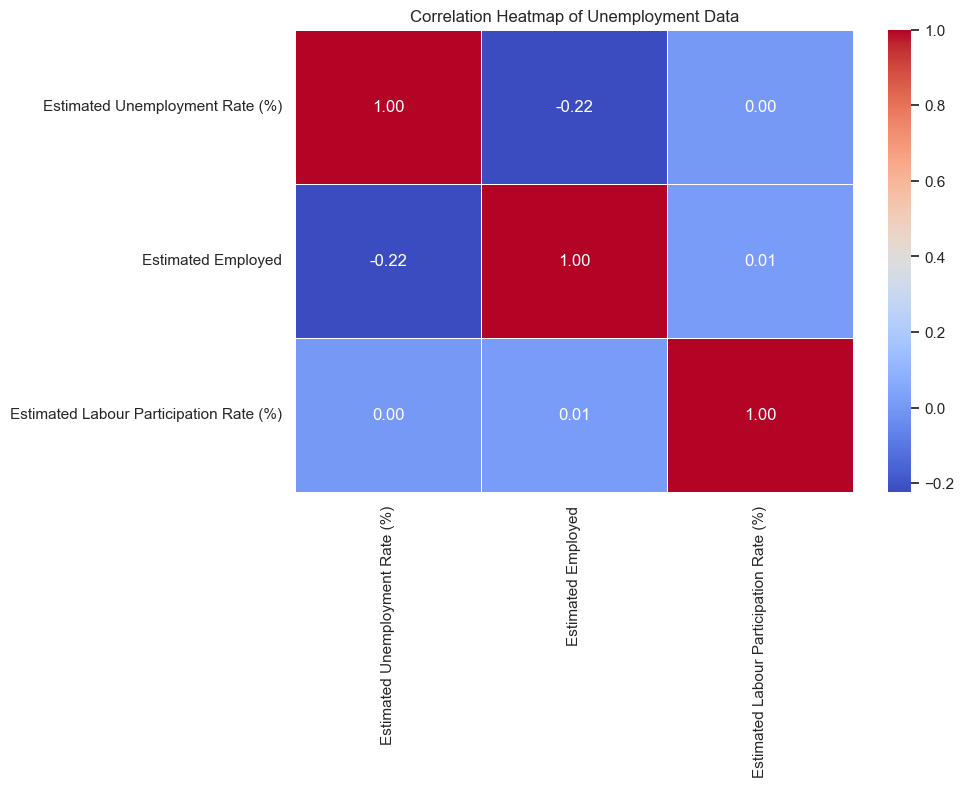

In [34]:
# Select numerical columns
correlation_data = df[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
]

# Calculate correlation
correlation_matrix = correlation_data.corr()

# Create heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Unemployment Data")

plt.savefig(
    "images/04_unemployment_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Average Unemployment Rate:
Period
During COVID    17.774363
Pre-COVID        9.509534
Name: Estimated Unemployment Rate (%), dtype: float64


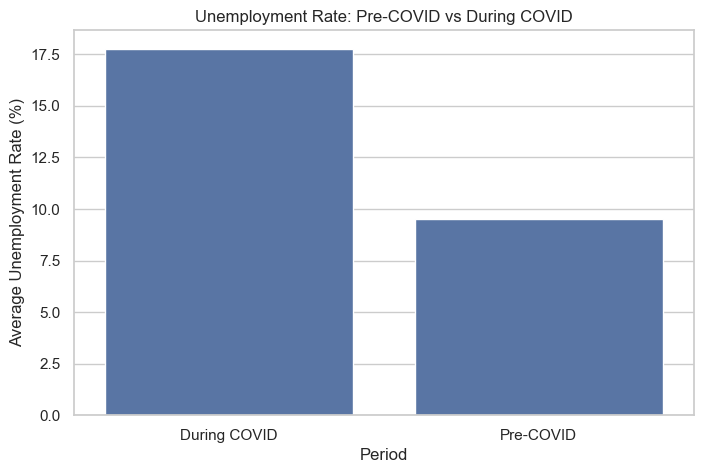

In [35]:
# Create a new period column
df["Period"] = np.where(
    df["Date"] < "2020-03-01",
    "Pre-COVID",
    "During COVID"
)

# Calculate average unemployment rate
covid_comparison = df.groupby("Period")[
    "Estimated Unemployment Rate (%)"
].mean()

print("Average Unemployment Rate:")
print(covid_comparison)

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=covid_comparison.index,
    y=covid_comparison.values
)

plt.title("Unemployment Rate: Pre-COVID vs During COVID")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")

plt.savefig(
    "images/05_covid_unemployment_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The average unemployment rate increased from 9.51%
before COVID-19 to 17.77% during the COVID-19 period.

This indicates a significant increase in unemployment
during the period covered by the dataset.

Average Unemployment Rate by Area:
Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64


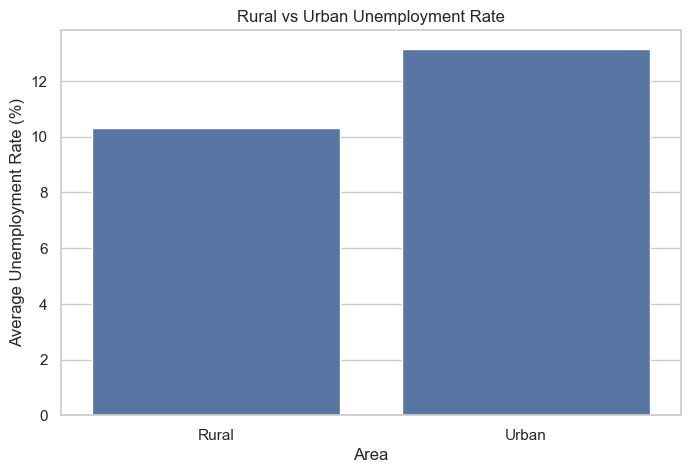

In [36]:
# Calculate average unemployment rate by area
area_unemployment = df.groupby("Area")[
    "Estimated Unemployment Rate (%)"
].mean()

print("Average Unemployment Rate by Area:")
print(area_unemployment)

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=area_unemployment.index,
    y=area_unemployment.values
)

plt.title("Rural vs Urban Unemployment Rate")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")

plt.savefig(
    "images/06_rural_urban_unemployment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Key Observations

1. The dataset contains 740 records covering 28 Indian regions from May 2019 to June 2020.
2. The average unemployment rate across the dataset was approximately 11.79%.
3. Tripura recorded the highest average unemployment rate of approximately 28.35% among the regions.
4. The average unemployment rate was 9.51% before COVID-19 and 17.77% during the COVID-19 period.
5. Urban areas recorded a higher average unemployment rate (13.17%) than rural areas (10.32%).
6. The correlation heatmap helped examine relationships between unemployment, employment and labour participation rates.

## Conclusion

In this project, I performed an exploratory data analysis of unemployment in India using Python.

I cleaned the dataset, handled missing values, converted date information into the correct format and explored unemployment patterns across different regions and areas.

I created visualizations including line charts, bar charts and a correlation heatmap to understand unemployment trends.

The analysis showed an increase in average unemployment during the COVID-19 period covered by the dataset. It also showed differences in unemployment rates across regions and between rural and urban areas.

This project helped me improve my skills in data cleaning, exploratory data analysis, data visualization and interpreting real-world datasets using Python.